In [1]:
%matplotlib inline

In [2]:
# Write your imports here
import pandas as pd

# Hypothesis Testing Exercise: Part 2
## Creating, testing, and comparing hypotheses on a real dataset
In this exercise, you'll be working with the Telco (telecom) customer churn dataset located [here](https://www.kaggle.com/datasets/blastchar/telco-customer-churn). Get to know it, download it, explore it - you know the drill!

### Problem 1. Prepare your analysis
First, before you even think about downloading the dataset, try to identify some good research questions. Formulate them in plain text (don't worry about the math formulations yet). Write your research questions below.

Then read and explore the dataset. Write any specific or odd details you find. **Pay especially close attention** to the target variable and its frequency (support).

**Research questions**

1. Is customer churn more common among customers with month-to-month
   contracts than among customers with longer-term contracts?
2. Do customers who leave have higher monthly charges on average
   than customers who stay?
3. Do customers who leave tend to have been with the company for
   fewer months than customers who stay?

In [3]:
# Write your code here

telco = pd.read_csv("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

print(f"Rows: {telco.shape[0]}, columns: {telco.shape[1]}")
display(telco.head())

churn = telco["Churn"]
display(pd.DataFrame({
    "Count": churn.value_counts(dropna=False),
    "Percent": churn.value_counts(normalize=True, dropna=False).mul(100).round(2),
}))

total_charges = pd.to_numeric(telco["TotalCharges"], errors="coerce")

print("TotalCharges dtype:", telco["TotalCharges"].dtype)
print("Missing TotalCharges after conversion:", total_charges.isna().sum())
print("Repeated customer IDs:", telco["customerID"].duplicated().sum())

Rows: 7043, columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


,Count,Percent
Churn,,
No,5174,73.46
Yes,1869,26.54


TotalCharges dtype: str
Missing TotalCharges after conversion: 11
Repeated customer IDs: 0


**Initial observations**

The dataset contains 7,043 records and 21 columns, with no duplicate
customer IDs. The target variable, `Churn`, is imbalanced: 1,869
customers (26.54%) left and 5,174 (73.46%) stayed.

`TotalCharges` was loaded as text. Converting it to numeric values
produced 11 missing values.

### Problem 2. Pick some "obvious" attributes

Find one variable that appears to differ between churners and non-churners, and produce a result that looks statistically significant.

Then stop and answer:

* Why did you pick this variable?
* Does statistical significance here automatically mean the effect is important?
* What would you want to check before saying anything strong?

In [4]:
# Write your code here
from scipy.stats import ttest_ind

churned = telco.loc[telco["Churn"] == "Yes", "tenure"].dropna()
stayed = telco.loc[telco["Churn"] == "No", "tenure"].dropna()

summary = pd.DataFrame({
    "Churn = Yes": churned.describe(),
    "Churn = No": stayed.describe(),
}).T
display(summary[["count", "mean", "50%", "std"]].round(2))

result = ttest_ind(churned, stayed, equal_var=False)
difference = churned.mean() - stayed.mean()
ci = result.confidence_interval()

print(f"Mean difference (Yes − No): {difference:.2f} months")
print(f"95% CI: [{ci.low:.2f}, {ci.high:.2f}] months")
print(f"Welch's t = {result.statistic:.2f}, p = {result.pvalue:.3e}")

,count,mean,50%,std
Churn = Yes,1869.0,17.98,10.0,19.53
Churn = No,5174.0,37.57,38.0,24.11


Mean difference (Yes − No): -19.59 months
95% CI: [-20.69, -18.49] months
Welch's t = -34.82, p = 1.195e-232


1. **Why did I pick tenure?**  
   I chose tenure because one of my research questions was whether
   customers who left had spent less time with the company.
   They had been customers for 19.59 fewer months on average
   (95% CI: 18.49 to 20.69 fewer months).

2. **Does statistical significance imply practical importance?**  
   No. The difference of nearly 20 months is large enough to investigate.
   Its practical value depends on whether it helps the company identify
   when to intervene to retain customers.

3. **What would I check before drawing a strong conclusion?**  
   I would check whether the difference persists within each contract
   type and how the observation period was defined. This comparison
   shows an association. It cannot establish that shorter tenure causes churn.

### Problem 3. Better formulation
Choose one of the following variables: tenure, internet service, contract, tech support, payment method.

For your chosen variable, write:
* The research question in plaintext
* Null and alternative hypotheses
* Type of variable - numerical or categorical
* What test(s) seem(s) appropriate
* At least one assumption or limitation that worries you

Only AFTER you've written the above, may you run the analysis. Show the results, discuss the applications. Don't forget the limitations too. Try to show more than one viewpoint.

**DO NOT** change the hypothesis after you've seen the data!!!

**Research question**

Does the proportion of customers who leave differ across month-to-month,
one-year, and two-year contracts?

**Hypotheses**

- H₀: The churn proportion is the same for all three contract types.
- H₁: At least one contract type has a different churn proportion.

**Variable types**

`Contract` is categorical with three levels. `Churn` is categorical
with two levels (`Yes` and `No`).

**Statistical test**

I will use a Pearson chi-square test of independence at α = 0.05.
I will report the churn percentage for each contract type and Cramér’s V
to describe the strength of the association.

**Assumptions and limitations**

The test assumes independent customer observations and sufficiently
large expected cell counts. Contract type may be related to customer
tenure, so the observed association alone cannot establish that changing
a customer's contract would change their likelihood of leaving.

In [5]:
# Write your code here
from math import sqrt
from scipy.stats import chi2_contingency

contract_churn = pd.crosstab(telco["Contract"], telco["Churn"])
display(contract_churn)

churn_percent = contract_churn["Yes"].div(contract_churn.sum(axis=1)) * 100
display(churn_percent.round(2).rename("Churn (%)").to_frame())

result = chi2_contingency(contract_churn)
n = contract_churn.to_numpy().sum()
cramers_v = sqrt(result.statistic / (n * (min(contract_churn.shape) - 1)))

print(f"χ²({result.dof}) = {result.statistic:.2f}, p = {result.pvalue:.3e}")
print(f"Cramér's V = {cramers_v:.3f}")
print(f"Smallest expected count = {result.expected_freq.min():.2f}")

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


,Churn (%)
Contract,
Month-to-month,42.71
One year,11.27
Two year,2.83


χ²(2) = 1184.60, p = 5.863e-258
Cramér's V = 0.410
Smallest expected count = 390.89


**Conclusion**

The chi-square test found a statistically significant association
between contract type and churn, χ²(2) = 1184.60, p = 5.863 × 10⁻²⁵⁸.
We reject the null hypothesis at α = 0.05. Cramér’s V was 0.410.
The smallest expected count was 390.89, so all expected counts
were above 5.

In this sample, churn was highest among customers with month-to-month
contracts (42.71%), followed by one-year (11.27%) and two-year
contracts (2.83%). The company could use this pattern to decide
where to investigate why customers leave.

Customers with different contract types may also differ in tenure.
I would compare customers with similar tenure before recommending
a contract change. This analysis cannot establish whether switching
to a longer contract would reduce churn.

### Problem 4. Monthly charges
Investigate whether the `MonthlyCharges` variable differs between churners and non-churners.

Do this **two** different ways:
* Permutation test (you can use the permutation feature importances code / tutorial from scikit-learn)
* One more of your choosing, e.g., Welch's t-test or  Mann - Whitney U

**Do the conclusions agree?** Why / why not? What do the conclusions tell you about the data? Don't forget to explain all your steps.

In [6]:
# Write your code here
import numpy as np
from scipy.stats import permutation_test, ttest_ind

charges_left = telco.loc[
    telco["Churn"] == "Yes", "MonthlyCharges"
].dropna().to_numpy()

charges_stayed = telco.loc[
    telco["Churn"] == "No", "MonthlyCharges"
].dropna().to_numpy()

def mean_difference(left, stayed):
    return np.mean(left) - np.mean(stayed)

permutation = permutation_test(
    (charges_left, charges_stayed),
    mean_difference,
    permutation_type="independent",
    alternative="two-sided",
    n_resamples=9_999,
    random_state=42,
)

welch = ttest_ind(charges_left, charges_stayed, equal_var=False)
ci = welch.confidence_interval(confidence_level=0.95)

print(f"Churn = Yes: n = {charges_left.size}, mean = {charges_left.mean():.2f}")
print(f"Churn = No:  n = {charges_stayed.size}, mean = {charges_stayed.mean():.2f}")
print(f"Mean difference (Yes − No): {permutation.statistic:.2f}")
print(f"Permutation test: p = {permutation.pvalue:.6g}")
print(f"Welch's t-test: t = {welch.statistic:.2f}, p = {welch.pvalue:.3e}")
print(f"95% CI for the mean difference: [{ci.low:.2f}, {ci.high:.2f}]")

Churn = Yes: n = 1869, mean = 74.44
Churn = No:  n = 5174, mean = 61.27
Mean difference (Yes − No): 13.18
Permutation test: p = 0.0002
Welch's t-test: t = 18.41, p = 8.592e-73
95% CI for the mean difference: [11.77, 14.58]


**Conclusion**

Customers who left paid an average of $74.44 per month (n = 1,869).
Customers who stayed paid an average of $61.27 (n = 5,174).
The estimated mean difference was $13.18 per month (95% Welch CI:
$11.77 to $14.58).

Both two-sided tests found a statistically significant difference at
the 5% level. The permutation test yielded p = 0.0002, and Welch’s
t-test yielded t = 18.41 and p = 8.592 × 10⁻⁷³. The permutation
p-value reached the minimum possible with 9,999 random permutations.
Welch’s test uses a t-distribution to calculate its p-value.

Higher monthly charges were associated with churn in the full sample.
These results do not establish that higher charges cause customers
to leave.

### Problem 5. Investigating subgroups: contract
Repeat the comparison that you did in Problem 4, this time including mongth charges _within each contract group_. Use the same method; don't forget to explain all your steps.

**Does the pattern remain in each contract group?** Is the pooled result (the one which does NOT take contracts into account) stronger than the within-group results? Why / why not?

In [7]:
contract_results = []

for contract, customers in telco.groupby("Contract"):
    left = customers.loc[
        customers["Churn"] == "Yes", "MonthlyCharges"
    ].dropna().to_numpy()

    stayed = customers.loc[
        customers["Churn"] == "No", "MonthlyCharges"
    ].dropna().to_numpy()

    permutation = permutation_test(
        (left, stayed),
        mean_difference,
        permutation_type="independent",
        alternative="two-sided",
        n_resamples=9_999,
        random_state=42,
    )

    welch = ttest_ind(left, stayed, equal_var=False)
    ci = welch.confidence_interval(confidence_level=0.95)

    contract_results.append({
        "Contract": contract,
        "n Yes": left.size,
        "n No": stayed.size,
        "Mean Yes": left.mean(),
        "Mean No": stayed.mean(),
        "Difference (Yes − No)": permutation.statistic,
        "95% CI lower": ci.low,
        "95% CI upper": ci.high,
        "Permutation p": permutation.pvalue,
        "Welch p": welch.pvalue,
    })

results = pd.DataFrame(contract_results).set_index("Contract")

display(results.style.format({
    "Mean Yes": "{:.2f}",
    "Mean No": "{:.2f}",
    "Difference (Yes − No)": "{:+.2f}",
    "95% CI lower": "{:.2f}",
    "95% CI upper": "{:.2f}",
    "Permutation p": "{:.3g}",
    "Welch p": "{:.3g}",
}))

,n Yes,n No,Mean Yes,Mean No,Difference (Yes − No),95% CI lower,95% CI upper,Permutation p,Welch p
Contract,,,,,,,,,
Month-to-month,1655,2220,73.02,61.46,+11.56,9.92,13.20,0.0002,2.29e-42
One year,166,1307,85.05,62.51,+22.54,18.26,26.83,0.0002,5.71e-21
Two year,48,1647,86.78,60.01,+26.76,18.21,35.32,0.0002,7.38e-08


**Conclusion**

Customers who left paid more per month on average within every contract
type. The estimated differences were $11.56 for month-to-month contracts,
$22.54 for one-year contracts, and $26.76 for two-year contracts.
Both tests found statistically significant differences at the 5% level
in all three groups.

The pooled difference of $13.18 was larger than the month-to-month
difference and smaller than both fixed-term differences. The pooled
estimate had the narrowest 95% confidence interval. The two-year group
had the widest interval, with only 48 customers who left.

Nearly 89% of customers who left had month-to-month contracts. The
pooled comparison reflects both the within-contract differences and
the different mix of contract types among customers who left and stayed.
These results show an association between monthly charges and churn
within each contract type.

### Problem 6. Gender (and protected attributes)
Gender shouldn't be associated with (or correlated to) churning. Is this the case? Why / why not? Follow the same process as you did in Problem 4.

Sometimes, lack of association is a desired outcome. We _would like_ our models to be fair, regardless of attributes like gender, race, age, disability, etc.

If you're interested to learn more, they are called _protected attributes_. We have different ways to assess whether a model is treating groups (especially protected groups) of people equally, and to ensure people's data remains private.

Make your analysis and discuss. Be **extremely careful** about the results (and their precise formulation), the confidence intervals you're choosing, the sample size you have, etc.

In [8]:
# Write your code here
gender_churn = pd.crosstab(telco["gender"], telco["Churn"])
gender_churn["Total"] = gender_churn["Yes"] + gender_churn["No"]
gender_churn["Churn (%)"] = (
    100 * gender_churn["Yes"] / gender_churn["Total"]
).round(2)
display(gender_churn)

female_churn = (
    telco.loc[telco["gender"] == "Female", "Churn"]
    .map({"Yes": 1, "No": 0}).dropna().to_numpy()
)
male_churn = (
    telco.loc[telco["gender"] == "Male", "Churn"]
    .map({"Yes": 1, "No": 0}).dropna().to_numpy()
)

permutation = permutation_test(
    (female_churn, male_churn),
    mean_difference,
    permutation_type="independent",
    alternative="two-sided",
    n_resamples=9_999,
    batch=200,
    random_state=42,
)

welch = ttest_ind(female_churn, male_churn, equal_var=False)
ci = welch.confidence_interval(confidence_level=0.95)

print(f"Difference (Female − Male): {100 * permutation.statistic:+.2f} pp")
print(f"Permutation p = {permutation.pvalue:.4f}")
print(f"Welch p = {welch.pvalue:.4f}")
print(f"95% CI: [{100 * ci.low:+.2f}, {100 * ci.high:+.2f}] pp")

Churn,No,Yes,Total,Churn (%)
gender,,,,
Female,2549,939,3488,26.92
Male,2625,930,3555,26.16


Difference (Female − Male): +0.76 pp
Permutation p = 0.4688
Welch p = 0.4699
95% CI: [-1.30, +2.82] pp


**Conclusion**

In this sample, 939 of 3,488 customers recorded as Female left (26.92%),
compared with 930 of 3,555 customers recorded as Male (26.16%).
The estimated difference was +0.76 percentage points (Female − Male).

Neither the two-sided permutation test (p = 0.4688) nor Welch’s test
(p = 0.4699) found a statistically significant difference at the 5% level.
The approximate 95% Welch confidence interval ranged from −1.30 to
+2.82 percentage points. The interval includes zero and allows for
small differences in either direction. A claim of practical equivalence
would require a predefined margin.

This analysis compares observed churn rates in the two recorded groups.
Assessing model fairness would require evaluating the model’s predictions
on held-out data, including how often it misses customers who actually
leave in each group.

### Problem 7. Break it! Or disprove it, as you wish...
Choose one of your own earlier findings and write **three versions** of the conclusion:
1. One that is carefully worded and evidence-based
2. One that is just as evidence-based, but it's overconfident
3. One causal that you can't prove from the data alone

Since 2 and 3 don't have enough ground, you should be able to disprove them, by using evidence (or lack thereof) in the data. Do that! Once again, don't forget to write out all your steps and describe your process carefully.

In fact, we often do this when we perform peer review. It's our duty to our colleagues to point out "holes" in their understanding and help them make better / stronger arguments.

* Optional: You could tryy several iterations of strengthening arguments for / against. It's a lot of fun, I promise! I've done it many times and it really helps to see your own biases and overcome them! :D

**Finding selected: Monthly charges and churn**

1. **Careful conclusion.** In this sample, customers who left paid
   $13.18 more per month on average than customers who stayed.
   The 95% Welch confidence interval for the pooled mean difference
   was $11.77 to $14.58.

2. **Overconfident conclusion.** Customers who leave pay about
   $13 more per month on average, regardless of their contract type.

3. **Causal conclusion.** Higher monthly charges make customers leave,
   so lowering their monthly bills by $13.18 would reduce churn.

**How I challenged the conclusions**

1. I started with the pooled comparison in Problem 4. Both tests
   found a statistically significant difference, and the estimated
   mean difference was $13.18.

2. I checked the comparisons within each contract type in Problem 5.
   The differences were $11.56 for month-to-month contracts, $22.54
   for one-year contracts, and $26.76 for two-year contracts.
   The direction was the same in all three groups. However, the
   95% confidence intervals for the one-year ($18.26 to $26.83)
   and two-year ($18.21 to $35.32) groups both excluded $13.18.
   This challenges the claim that the pooled estimate describes
   every contract type.

3. I checked what evidence the analysis provides about a price cut.
   The data compare existing customer bills. Customers were not
   randomly assigned to different prices, and their bills may
   reflect differences in service packages or tenure. Comparing
   customers within each contract type addresses one of those
   differences. The effect of a $13.18 price cut remains unknown.
   A randomized discount trial with a fixed follow-up period could
   test whether the price cut reduces churn.

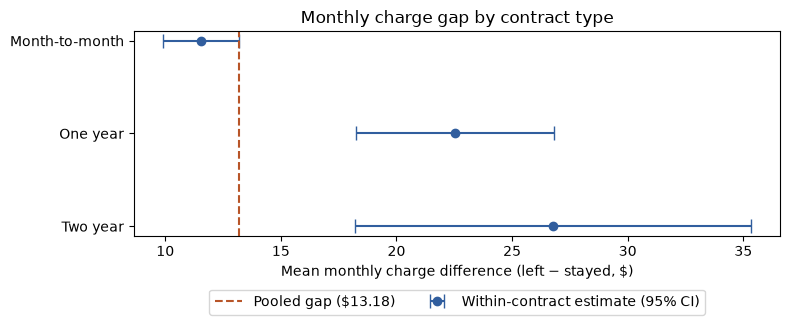

In [9]:
import matplotlib.pyplot as plt

contract_order = ["Month-to-month", "One year", "Two year"]
plot_data = results.loc[contract_order]

difference = plot_data["Difference (Yes − No)"]
lower = plot_data["95% CI lower"]
upper = plot_data["95% CI upper"]

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.errorbar(
    difference, contract_order,
    xerr=[difference - lower, upper - difference],
    fmt="o", capsize=5, color="#315E9E",
    label="Within-contract estimate (95% CI)",
)
ax.axvline(13.18, linestyle="--", color="#B85528", label="Pooled gap ($13.18)")
ax.invert_yaxis()
ax.set_xlabel("Mean monthly charge difference (left − stayed, $)")
ax.set_title("Monthly charge gap by contract type")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.23), ncol=2)
fig.tight_layout()
plt.show()

### Problem 8. Which result would you actually act on?
Imagine you are presenting to a company that wants to reduce churn.

Based on your work so far, choose **two** findings you would show first.
You are allowed to add other things / hypotheses / analyses / visualizations, etc. Feel free to do whatever you wish with the dataset; as long as it's evidence-based and well-described.

For each one of the two findings, explain:
* Why do you think it is statistically credible?
* Why do you think it matters _in practice_?
* What further evidence (or next steps) you would want before you recommend an action?

**1. Contract type and churn**

- **Statistical evidence.** Churn was 42.71% among customers with
  month-to-month contracts, 11.27% among those with one-year contracts,
  and 2.83% among those with two-year contracts. The chi-square test
  found a significant association (χ²(2) = 1184.60, p < 0.001,
  Cramér’s V = 0.410).
- **Practical relevance.** Month-to-month customers accounted for
  1,655 of the 1,869 customers who left. I would start by investigating
  cancellation reasons in this group.
- **Evidence needed before acting.** I would check whether the difference
  persists among customers with similar tenure and service packages.
  Before rolling out a retention offer, I would test it in a randomized
  pilot and measure churn and net revenue.

**2. Monthly charges and churn**

- **Statistical evidence.** Customers who left paid $13.18 more per month
  on average (95% Welch CI $11.77 to $14.58). Both tests found a
  significant difference. The average gap was positive within all three
  contract types, ranging from $11.56 to $26.76.
- **Practical relevance.** The difference makes it worth investigating
  whether customers who leave see poor value in particular plans or
  service bundles.
- **Evidence needed before acting.** I would compare customers on
  similar plans and review their cancellation reasons. A randomized
  discount trial could then estimate whether a lower price reduces
  churn enough to cover the cost of the discount.

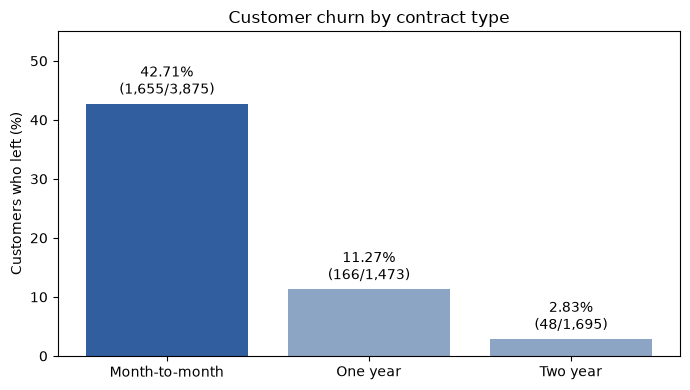

In [10]:
# Write your code here
counts = contract_churn.loc[contract_order]
total = counts[["Yes", "No"]].sum(axis=1)
churn_rate = 100 * counts["Yes"] / total

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(churn_rate.index, churn_rate, color=["#315E9E", "#8DA5C4", "#8DA5C4"])
ax.bar_label(
    bars,
    labels=[
        f"{rate:.2f}%\n({left:,}/{group_size:,})"
        for rate, left, group_size in zip(churn_rate, counts["Yes"], total)
    ],
    padding=4,
)
ax.set_ylim(0, 55)
ax.set_ylabel("Customers who left (%)")
ax.set_title("Customer churn by contract type")
fig.tight_layout()
plt.show()

Month-to-month customers had the highest observed churn rate (42.71%) and accounted for 1,655 of the 1,869 customers who left. This is the first group I would investigate for reasons for leaving.
